# Choosing the semantic cache threshold

**Question.** Cordon's semantic cache reuses a stored answer when a new question is *almost the same* as an earlier one. How similar must two questions be?

**Why it matters.** A cache hit saves the full cost of a model call. A *wrong* cache hit gives the user the answer to a different question - that is worse than a missed saving. So the threshold is a trade-off between two measured quantities:

- **hit rate** - the share of real duplicate questions the cache catches (savings);
- **wrong-hit rate** - the share of cache answers that belong to a different question (risk).

**Decision rule.** The most hits at a wrong-hit rate of about 1% or less.

**Cordon's matching rule** (`src/savings/cache.py`): a hit needs embedding cosine similarity >= threshold **and** identical guard tokens - the same negation words, the same numbers and (added after this analysis) the same names in the same order.

The calculation code lives in `evaluation/semantic_threshold.py`, so it is tested and reusable; this notebook runs it and explains the result.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve

from src.savings import quality
from src.savings.cache import extract_negation_and_number_tokens, semantic_guard_tokens
from evaluation import semantic_threshold as st

SEED = 42
THRESHOLDS = np.round(np.arange(0.85, 0.996, 0.005), 3)
pd.set_option("display.max_colwidth", 80)

## 1. Data

**Quora Question Pairs** (QQP, the validation split of the GLUE benchmark): 40,430 pairs of real user questions, each labelled by people as *duplicate* (1) or *not duplicate* (0).

Two properties to keep in mind:

- The pairs were selected because they look alike. Even the non-duplicates are usually on the same topic, so this is a *hard* test for wrong hits - harder than everyday traffic, where most questions are unrelated.
- The labels contain human mistakes (a known property of QQP). That matters at high similarity, where most pairs are near-identical text - see section 5.

The data is used only to choose one number. The dataset itself is downloaded on demand and never committed (`data/external/` is gitignored); this notebook shows a few dozen example pairs as part of the analysis. Check Quora's terms before any other use.

In [2]:
from huggingface_hub import hf_hub_download

path = hf_hub_download(repo_id="nyu-mll/glue", repo_type="dataset",
                       filename="qqp/validation-00000-of-00001.parquet", local_dir=str(ROOT / "data/external/glue"))
pairs = st.load_pairs(path, n=40430, seed=SEED)
print(len(pairs), "pairs;", f"{pairs.label.mean():.1%} labelled duplicate")
pairs.head(3)

40430 pairs; 36.8% labelled duplicate


,question1,question2,label
0,What attributes would have made you highly desirable in ancient Rome?,How I GET OPPERTINUTY TO JOIN IT COMPANY AS A FRESHER?,0
1,How can one develop thinking skills?,How do I increase my thinking skills?,1
2,How do you know if you are in love with someone?,When do you know that you are in love?,1


**Tune / test split.** The threshold is chosen on the *tune* half only. The *test* half is used once, at the end, to check the choice on pairs it has never seen - otherwise the result would flatter itself.

In [3]:
tune, test = pairs.iloc[: len(pairs) // 2], pairs.iloc[len(pairs) // 2 :]
scored = {}
for split_name, split in (("tune", tune), ("test", test)):
    scored[(split_name, "old")] = st.pair_scores(split, quality.embed_texts, guard_fn=extract_negation_and_number_tokens)
    scored[(split_name, "new")] = st.pair_scores(split, quality.embed_texts, guard_fn=semantic_guard_tokens)
print({k: len(v) for k, v in scored.items()})

{('tune', 'old'): 20215, ('tune', 'new'): 20215, ('test', 'old'): 20215, ('test', 'new'): 20215}


## 2. How well does similarity separate duplicates at all?

The ROC curve shows, for every possible threshold, the share of duplicates caught against the share of non-duplicates wrongly let through. AUC = 1 is perfect, 0.5 is guessing.

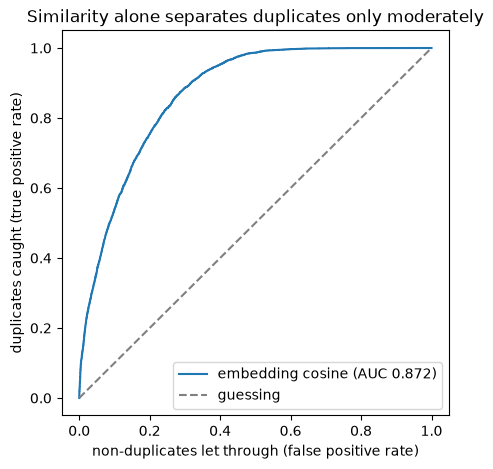

In [4]:
s = scored[("tune", "old")]
auc = roc_auc_score(s.label, s.cosine)
fpr, tpr, _ = roc_curve(s.label, s.cosine)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, label=f"embedding cosine (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="guessing")
ax.set_xlabel("non-duplicates let through (false positive rate)")
ax.set_ylabel("duplicates caught (true positive rate)")
ax.set_title("Similarity alone separates duplicates only moderately")
ax.legend(loc="lower right")
plt.show()

An AUC around 0.8 means similarity alone is a moderate signal: many non-duplicates look very similar. That is why the threshold has to be high, and why the extra guard tokens matter.

## 3. The trade-off, threshold by threshold (tune split)

In [5]:
old = st.sweep(scored[("tune", "old")], THRESHOLDS)
new = st.sweep(scored[("tune", "new")], THRESHOLDS)
show = [0.90, 0.93, 0.95, 0.96, 0.97, 0.98, 0.99]
table = old[old.threshold.isin(show)].merge(new[new.threshold.isin(show)], on="threshold", suffixes=("_old", "_new"))
table[["threshold", "hits_old", "wrong_hit_rate_old", "hit_rate_old", "hits_new", "wrong_hit_rate_new", "hit_rate_new"]].round(3)

,threshold,hits_old,wrong_hit_rate_old,hit_rate_old,hits_new,wrong_hit_rate_new,hit_rate_new
0,0.90,3634,0.195,0.399,2741,0.169,0.311
1,0.93,2467,0.155,0.284,1911,0.134,0.226
2,0.95,1709,0.117,0.206,1340,0.099,0.165
3,0.96,1307,0.106,0.159,1023,0.082,0.128
4,0.97,935,0.088,0.116,739,0.066,0.094
5,0.98,601,0.062,0.077,491,0.051,0.064
6,0.99,275,0.065,0.035,224,0.058,0.029


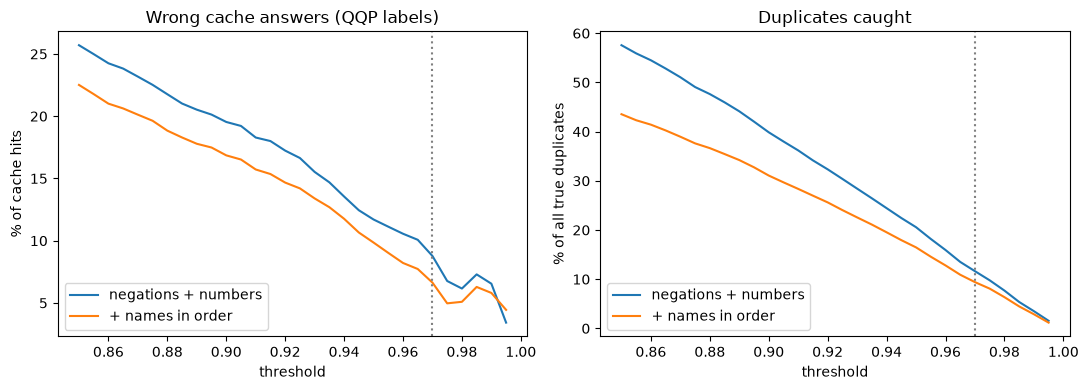

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for frame, label in ((old, "negations + numbers"), (new, "+ names in order")):
    axes[0].plot(frame.threshold, frame.wrong_hit_rate * 100, label=label)
    axes[1].plot(frame.threshold, frame.hit_rate * 100, label=label)
axes[0].set_title("Wrong cache answers (QQP labels)")
axes[0].set_ylabel("% of cache hits")
axes[1].set_title("Duplicates caught")
axes[1].set_ylabel("% of all true duplicates")
for ax in axes:
    ax.axvline(0.97, color="grey", linestyle=":")
    ax.set_xlabel("threshold")
    ax.legend()
plt.tight_layout()
fig.savefig(ROOT / "reports" / "semantic_threshold.png", dpi=120)
plt.show()

Two things stand out:

1. **Lowering the threshold quickly makes things worse.** Below 0.97 the wrong-hit rate climbs steeply.
2. **Above about 0.98 the wrong-hit rate stops falling** - it levels off around 6-7%. A higher threshold cannot fix it. That floor needs a closer look.

## 4. What are the "wrong" hits? (before the name guard)

The highest-similarity wrong hits under the old rule:

In [7]:
s = scored[("tune", "old")]
s[st.is_hit(s, 0.97) & (s.label == 0)].sort_values("cosine", ascending=False)[["cosine", "question1", "question2"]].head(12)

,cosine,question1,question2
12322,1.000000,What do you think of this video ?,What do you think of this video?
4974,0.996775,What are some of the best ways to prevent deforestation?,What are the best ways to prevent deforestation?
16795,0.996368,Do dominant vendors in a space ever force customers to sign non-competes?,Do dominant customers in a space ever force vendors to sign non-competes?
13605,0.995271,Why are natural resources important for us?,Why natural resources are important for us?
2644,0.994851,What is the difference between eddy current loss & hysteresis loss?,What is the difference between Hysteresis loss & Eddy current loss?
3892,0.994560,What do north indian boys think about south Indian girls?,What do North Indian girls think about South Indian boys?
18553,0.994509,"Which is a suitable solar panel installation provider in Chandler, Arizona AZ?","Which is a suitable solar panel installation provider near Chandler, Arizona..."
4026,0.994505,What is it like having no friends?,What is it like having no friends at all?
1686,0.994400,What is actually mep (mechanical electrical plumbing)?,What is MEP (mechanical electrical plumbing)?
5801,0.993958,"What are the chances of catching herpes, chlamydia, gonorrhea, HPV and syphi...","What are the chances of catching herpes, chlamydia, gonorrhea, HPV and syphi..."


Many are the *same* question with a different name or a swapped order - "rehab center in Bartow County" vs "in Towns County", "cheaper in India than the UK" vs the reverse. An embedding barely notices such a change, but the right answer is different.

**Fix built into Cordon:** the guard tokens now also require the same capitalised words (names, places, products) in the same order (`cache.extract_name_tokens`). In the cache table those names are stored only as keyed hashes, never as text. Section 3 shows the effect: at 0.97 the wrong-hit rate drops by about a fifth to a quarter, at the cost of some hits.

## 5. Label noise: how many remaining "wrong" hits are really wrong?

A reproducible random sample of 30 remaining wrong hits at 0.97 (new rule, tune split), each judged by reading both questions: would the cached answer correctly answer the new question?

In [8]:
s = scored[("tune", "new")]
audit = s[st.is_hit(s, 0.97) & (s.label == 0)].sample(30, random_state=SEED)[["cosine", "question1", "question2"]].reset_index(drop=True)
audit

,cosine,question1,question2
0,0.977621,How can you inspire me?,How can I inspire you?
1,0.971110,How can I convert volts to watts?,How do you convert watts to volts?
2,0.990446,What are the reason for ring warm infections?,What are the reasons for ring warm infections?
3,0.972286,What does this painting means?,What is the meaning of this painting?
4,0.979374,What's the best haircut for me and my beard?,What's the best haircut and beard for me?
5,0.974917,Do you prefer Quora over Facebook?,How many of you prefer Quora over Facebook?
6,0.986559,How do I know when to sell a real estate property?,How do you know when to sell a real estate property?
7,0.971657,What are the free cpt video lectures app?,What are the free app and websites which provide free video lectures for cpt?
8,0.987447,Which of the following is true about the graph of the rational function shown?,Which of the following is true about the graph of the rational function?
9,0.980864,How do you start an ecommerce business?,How do I start ecommerce business?


In [9]:
# Verdict per row of the sample above, judged by reading both questions:
# "same"      - the QQP label is a mistake: one answer fits both questions;
# "different" - a real wrong hit: the cached answer would be wrong;
# "unclear"   - the questions overlap but are not quite the same.
VERDICTS = {
    0: "different",  # inspire me / I inspire you - roles reversed
    1: "different",  # volts to watts / watts to volts - direction reversed
    2: "same", 3: "same", 4: "same",
    5: "unclear",    # "do you prefer" / "how many of you prefer"
    6: "same", 7: "same", 8: "same", 9: "same", 10: "same", 11: "same", 12: "same",
    13: "different", # married men & ex-girlfriends / married girls & ex-boyfriends
    14: "same", 15: "same", 16: "same", 17: "same", 18: "same", 19: "same", 20: "same",
    21: "unclear",   # repair / repair and installation
    22: "different", # when / who performed the first appendectomy
    23: "different", # guys girls like / girls guys like - roles reversed
    24: "same", 25: "same",
    26: "different", # vendors force customers / customers force vendors
    27: "same",
    28: "different", # shaving cream as conditioner / conditioner as shaving cream
    29: "same",
}
counts = pd.Series(VERDICTS).value_counts()
print(counts.to_dict())
real_share_low = counts.get("different", 0) / len(VERDICTS)
real_share_high = (counts.get("different", 0) + counts.get("unclear", 0)) / len(VERDICTS)
print(f"share of QQP 'wrong' hits that are really wrong: {real_share_low:.0%} - {real_share_high:.0%}")

{'same': 21, 'different': 7, 'unclear': 2}
share of QQP 'wrong' hits that are really wrong: 23% - 30%


## 6. Result on the held-out test split

In [10]:
rows = []
for rule in ("old", "new"):
    s = scored[("test", rule)]
    t = st.sweep(s, [0.97]).iloc[0]
    low, high = st.bootstrap_wrong_hit_ci(s, 0.97)
    rows.append({"rule": rule, "hits": int(t.hits), "wrong_hit_rate (QQP labels)": f"{t.wrong_hit_rate:.1%}",
                 "95% CI": f"{low:.1%} - {high:.1%}", "hit_rate": f"{t.hit_rate:.1%}"})
pd.DataFrame(rows)

new_rate = st.sweep(scored[("test", "new")], [0.97]).iloc[0].wrong_hit_rate


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    """95% Wilson interval for a proportion k/n - honest for small samples such as a 30-pair audit."""
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * ((p * (1 - p) / n + z * z / (4 * n * n)) ** 0.5) / (1 + z * z / n)
    return centre - half, centre + half


low, _ = wilson(counts.get("different", 0), len(VERDICTS))
_, high = wilson(counts.get("different", 0) + counts.get("unclear", 0), len(VERDICTS))
print(f"point estimate: {new_rate * real_share_low:.1%} (only 'different' counted)")
print(f"honest range:   {new_rate * low:.1%} - {new_rate * high:.1%} (95% Wilson interval of the audit share x the measured rate)")

point estimate: 1.8% (only 'different' counted)
honest range:   0.9% - 3.6% (95% Wilson interval of the audit share x the measured rate)


## 7. Conclusion

**Measured** (held-out test split, 20,215 pairs, QQP labels): at the default threshold 0.97 the old rule served wrong answers on 9.4% of semantic hits; requiring the same names in the same order brings that to 7.6%, at the cost of catching 9.8% instead of 11.7% of duplicates. The name guard is now part of Cordon.

**Corrected for label noise** (30-pair audit above, one reader, not blind): about a quarter of the remaining "wrong" hits are really wrong. With the uncertainty of a 30-pair sample, the **real wrong-hit rate is roughly 1-4%** (point estimate about 2%) - most likely above the 1% target.

**Why not simply raise the threshold?** Above about 0.98 the wrong-hit rate stops falling while the savings keep shrinking. The remaining errors are reversed roles and directions with ordinary words ("guys/girls", "vendors/customers", "volts to watts / watts to volts"). Cosine similarity between two separate embeddings cannot see those; no threshold can fix them.

**Decision.**
1. Keep `semantic_threshold: 0.97` (the starting value - it was kept, not selected: no threshold met the 1% target). A lower value is clearly worse; a higher one buys little safety for a large loss of savings.
2. Keep the name guard (built into `cache.py`; names stored only as keyed hashes).
3. The semantic cache stays **off by default** and is recommended only for FAQ-style traffic, where reversed-role questions are rare. The exact cache has no such risk.
4. Next step, if the semantic cache must become safer: re-check each candidate hit with a small cross-encoder (a model that reads both questions together) - and re-run this notebook to measure the gain.

**Caveat.** QQP pairs are not what a cache sees (a cache compares a new question with its nearest stored one), so the rate on real traffic is unknown until it is measured there.